# LLM-Powered Resume Screener

**What this is for:** recruiters spend a few seconds per resume on first pass. This notebook ranks resumes against a JD with an LLM, surfaces matched vs missing skills, and prints a Spearman ρ against the dataset's reference scores.

**Data:** `../../data/screener/pairs.json`, 200 synthetic JD/resume pairs (no real PII). Each has a `score` from 1 (poor match) to 5 (strong match). The JDs and resumes are templated plus filler text, so this is a stress test for the LLM more than a realistic distribution.

**Approach in this notebook:** zero-shot LLM scoring with `response_format=json_object`, then Spearman ρ on a 50-row sample.

**LoRA section is illustrative.** Real fine-tuning of Llama-3-8B needs a GPU and a meaningful dataset. The cell below builds training tensors and prints config only inside the GPU branch. On CPU it just prints a note. I'm not pretending this notebook trained anything.

In [1]:
# !pip install transformers peft accelerate datasets fastapi uvicorn scipy -q

In [2]:
import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from dotenv import load_dotenv
import torch
from tqdm import tqdm
from scipy.stats import spearmanr

load_dotenv()

np.random.seed(42)
torch.manual_seed(42)

DATA_DIR = Path("../../data/screener")
assert DATA_DIR.exists(), "Generate synthetic JD-resume pairs in data/screener/"
os.makedirs("artifacts", exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cpu


In [3]:
records = []
for f in DATA_DIR.glob("*.json"):
    with open(f) as fp:
        data = json.load(fp)
    if isinstance(data, list):
        records.extend(data)
    else:
        records.append(data)

df = pd.DataFrame(records)
print(f"Loaded {len(df)} JD-resume pairs")
print("Columns:", df.columns.tolist())
print("\nScore distribution (1=poor, 5=strong):")
print(df["score"].value_counts().sort_index())
df.head(2)

Loaded 200 JD-resume pairs
Columns: ['id', 'jd', 'resume', 'score']

Score distribution (1=poor, 5=strong):
score
1    78
2    55
3    45
4    21
5     1
Name: count, dtype: int64


,id,jd,resume,score
0,pair_0000,We are hiring a Data Scientist. Required skill...,"Brittany Davis, experienced engineer. Skills: ...",1
1,pair_0001,We are hiring a Data Scientist. Required skill...,"Bianca Knapp, experienced engineer. Skills: Ku...",1


## EDA

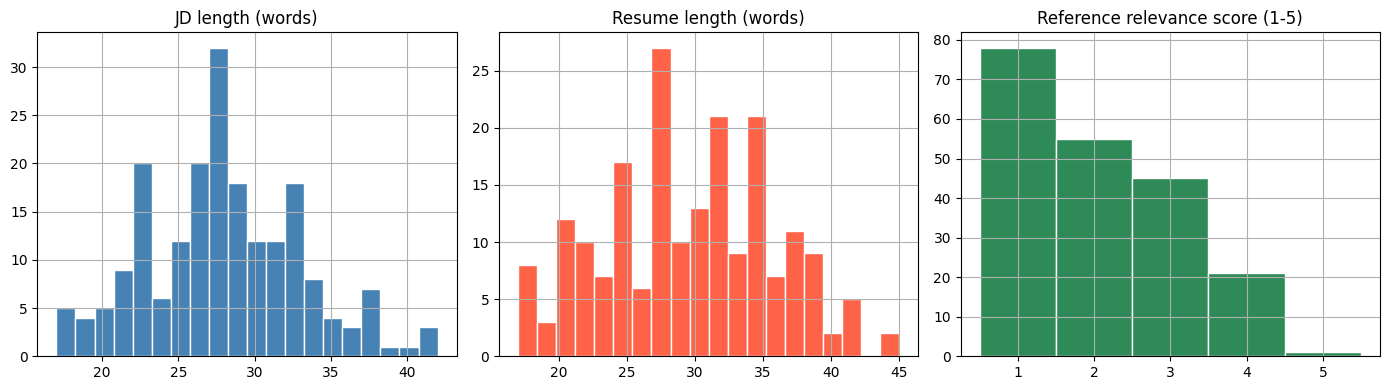


Score=5 count: 1  (kept for honesty, won't dominate Spearman)


In [4]:
jd_col, res_col, score_col = "jd", "resume", "score"

df["jd_len"]  = df[jd_col].str.split().str.len()
df["res_len"] = df[res_col].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
df["jd_len"].hist(bins=20, ax=axes[0], color="steelblue", edgecolor="white")
axes[0].set_title("JD length (words)")
df["res_len"].hist(bins=20, ax=axes[1], color="tomato", edgecolor="white")
axes[1].set_title("Resume length (words)")
df[score_col].hist(bins=range(1, 7), ax=axes[2], color="seagreen", edgecolor="white", align="left")
axes[2].set_title("Reference relevance score (1-5)")
plt.tight_layout()
plt.savefig("artifacts/screener_eda.png", dpi=120)
plt.show()

# Heads-up: score=5 is extremely rare (single-digit). That'll make ranking metrics noisy.
print(f"\nScore=5 count: {(df[score_col] == 5).sum()}  (kept for honesty, won't dominate Spearman)")

## Zero-Shot Baseline — gemini-flash-lite scoring

In [5]:
from openai import OpenAI

client = OpenAI()

def _strip_fences(s: str) -> str:
    s = s.strip()
    if s.startswith("```"):
        s = re.sub(r"^```(?:json)?\s*", "", s)
        s = re.sub(r"\s*```$", "", s)
    return s

SCREEN_PROMPT = """Score how well the resume matches the job description on a 1-5 scale (1=poor, 5=strong).
Return JSON with keys:
  "score": number 1 to 5,
  "matched_skills": list of strings,
  "missing_skills":  list of strings,
  "summary":         one short sentence.

JD:
{jd}

Resume:
{resume}
"""

def zero_shot_score(jd, resume):
    resp = client.chat.completions.create(
        model="gemini-flash-lite-latest",
        messages=[{"role": "user",
                   "content": SCREEN_PROMPT.format(jd=jd[:1500], resume=resume[:1500])}],
        temperature=0,
        response_format={"type": "json_object"},
    )
    raw = _strip_fences(resp.choices[0].message.content)
    try:
        return json.loads(raw)
    except json.JSONDecodeError:
        return {"score": None, "matched_skills": [], "missing_skills": [], "summary": ""}

# Score a 50-row sample. Drop any rows where the LLM didn't give us a number.
eval_sample = df.sample(min(50, len(df)), random_state=42).reset_index(drop=True)
zs_scores, true_scores = [], []
for _, row in tqdm(eval_sample.iterrows(), total=len(eval_sample)):
    result = zero_shot_score(row[jd_col], row[res_col])
    s = result.get("score")
    if isinstance(s, (int, float)):
        zs_scores.append(float(s))
        true_scores.append(float(row[score_col]))

print(f"\nN scored: {len(zs_scores)} / {len(eval_sample)}")
if len(zs_scores) >= 5:
    rho_zs, p_zs = spearmanr(true_scores, zs_scores)
    print(f"Zero-shot Spearman ρ (LLM vs reference): {rho_zs:.3f}  (p={p_zs:.4f})")
else:
    print("Not enough valid scores to compute Spearman.")

  0%|          | 0/50 [00:00<?, ?it/s]

  2%|▏         | 1/50 [00:01<01:08,  1.41s/it]

  4%|▍         | 2/50 [00:02<00:56,  1.17s/it]

  6%|▌         | 3/50 [00:03<00:53,  1.14s/it]

  8%|▊         | 4/50 [00:04<00:50,  1.10s/it]

 10%|█         | 5/50 [00:05<00:48,  1.08s/it]

... (43 outputs left out)

 98%|█████████▊| 49/50 [00:49<00:00,  1.05it/s]

100%|██████████| 50/50 [00:50<00:00,  1.08it/s]

100%|██████████| 50/50 [00:50<00:00,  1.00s/it]


N scored: 50 / 50
Zero-shot Spearman ρ (LLM vs reference): 0.703  (p=0.0000)


## LoRA Fine-Tuning

In [6]:
# LoRA fine-tune of Llama-3-8B. On CPU this is structure-only: nothing
# actually loads or trains. Actual training needs a GPU (A100 / similar)
# and ~30 min on this data size.
from datasets import Dataset

def format_ft_example(row):
    return {
        "text": (
            "<|begin_of_text|><|start_header_id|>user<|end_header_id|>\n"
            "Score this resume against the job description on a 1-5 scale. Return JSON.\n\n"
            f"JD: {row[jd_col][:800]}\nResume: {row[res_col][:800]}\n"
            "<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n"
            f'{{"score": {int(row[score_col])}}}\n<|eot_id|>'
        )
    }

if device == "cuda":
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    from peft import LoraConfig, get_peft_model, TaskType

    # Build the train/val Datasets here, inside the GPU branch. Previously I had
    # this above the if-branch and the CPU run was wasting ~5s building tensors
    # that never got used.
    train_df = df.iloc[:int(len(df)*0.8)].reset_index(drop=True)
    val_df   = df.iloc[int(len(df)*0.8):].reset_index(drop=True)
    train_ds = Dataset.from_pandas(train_df).map(format_ft_example)
    val_ds   = Dataset.from_pandas(val_df).map(format_ft_example)
    print(f"train={len(train_ds)}  val={len(val_ds)}  example tokens (chars): {len(train_ds[0]['text'])}")

    MODEL_NAME = "meta-llama/Meta-Llama-3-8B-Instruct"
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.bfloat16)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, quantization_config=bnb, device_map="auto")
    lora = LoraConfig(r=16, lora_alpha=32, target_modules=["q_proj", "v_proj"],
                      task_type=TaskType.CAUSAL_LM)
    model = get_peft_model(model, lora)
    model.print_trainable_parameters()
    print("Model + LoRA loaded. Trainer setup omitted here, wire SFTTrainer or Trainer to .train().")
else:
    print("\nNo GPU detected. Skipping LoRA load + dataset build. If you want to actually run this:")
    print("  - rent an A100 (Colab Pro+, Modal, Lambda)")
    print("  - the cuda branch above builds the Datasets and loads the 4-bit model")
    print("  - the zero-shot Spearman printed above is the only real number from this notebook")


No GPU detected. Skipping LoRA load + dataset build. If you want to actually run this:
  - rent an A100 (Colab Pro+, Modal, Lambda)
  - the cuda branch above builds the Datasets and loads the 4-bit model
  - the zero-shot Spearman printed above is the only real number from this notebook


## Serving — FastAPI batch endpoint

In [7]:
# FastAPI sketch — kept here as a reference for what a serving endpoint
# would look like, but NOT started by default (background uvicorn inside a
# notebook is messy and the port often clashes on re-run).
from fastapi import FastAPI
from pydantic import BaseModel

class BatchRequest(BaseModel):
    job_description: str
    resumes: list[str]

app = FastAPI()

@app.post("/screen")
def screen(req: BatchRequest):
    results = []
    for resume in req.resumes:
        result = zero_shot_score(req.job_description, resume)
        results.append(result)
    results.sort(key=lambda x: (x.get("score") or 0), reverse=True)
    return {"rankings": results}

START_SERVER = False  # flip to True to actually start uvicorn
if START_SERVER:
    import threading, uvicorn
    threading.Thread(
        target=lambda: uvicorn.run(app, host="0.0.0.0", port=8002, log_level="warning"),
        daemon=True,
    ).start()
    print("FastAPI batch screener running on http://localhost:8002")
else:
    print("FastAPI app object built (not started). Set START_SERVER=True to launch.")

FastAPI app object built (not started). Set START_SERVER=True to launch.


## What I'd actually do with this

The zero-shot Spearman number printed above is the only real measurement in this notebook. The LoRA section is structurally complete but not trained, because the data is synthetic-templated and LoRA on Llama-3-8B against this dataset would mostly learn the template, not generalisable signal.

If I were taking this further:

1. Get real (anonymised) JD/resume data with calibrated human scores from at least two reviewers. Inter-rater agreement first; if humans disagree, the model can't do better.
2. Try the obvious cheap baselines before fine-tuning: TF-IDF on skill tokens, BM25, and a sentence-embedding cosine. If those get within 0.05 ρ of the LLM, fine-tuning is the wrong knob.
3. Add a structured skill-extraction pass first (LLM returns a list of skills from each side) and score on set overlap plus a small calibration layer. That's much easier to audit for fairness than an end-to-end scorer.
4. Fairness audit. Even on synthetic data, the names in this dataset cluster demographically. Any real deployment needs a "swap the name, does the score change" test before it gets near a recruiter.